# Employee Salary Prediction
Predict an employee's **annual salary (in LPA)** from age, education, experience, job level and other details.

**Name:** Vishu  
**Roll No:** 2026m01410018

In [1]:
import warnings
warnings.filterwarnings('ignore')
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
os.makedirs('charts', exist_ok=True)
stats = {}

## 1. Load the dataset

In [2]:
data = pd.read_csv('employee_salary_dataset.csv')
data.head()

,Employee_ID,Age,Gender,Education,Experience_Years,Department,Job_Level,Performance_Rating,Certifications,Overtime_Hours,Remote_Work,City,Company_Tenure,Projects_Completed,Skill_Score,Annual_Salary_LPA
0,EMP10001,28.0,Male,Master,6.0,Operations,Junior,1,4,15,Yes,Chennai,6,5,97.0,35.24
1,EMP10002,26.0,Female,Bachelor,5.0,Operations,Junior,2,3,32,No,Delhi,0,18,62.0,35.87
2,EMP10003,31.0,Female,Bachelor,5.0,Marketing,Junior,4,5,17,Yes,Hyderabad,4,7,98.0,35.40
3,EMP10004,59.0,Female,Bachelor,29.0,Sales,Lead,3,0,46,No,Mumbai,14,18,57.0,73.05
4,EMP10005,23.0,Female,Bachelor,0.0,Sales,Junior,2,4,5,Yes,Hyderabad,0,28,56.0,28.83


In [3]:
data.shape

(5020, 16)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         5020 non-null   str    
 1   Age                 4960 non-null   float64
 2   Gender              5020 non-null   str    
 3   Education           5020 non-null   str    
 4   Experience_Years    4960 non-null   float64
 5   Department          5020 non-null   str    
 6   Job_Level           5020 non-null   str    
 7   Performance_Rating  5020 non-null   int64  
 8   Certifications      5020 non-null   int64  
 9   Overtime_Hours      5020 non-null   int64  
 10  Remote_Work         5020 non-null   str    
 11  City                5020 non-null   str    
 12  Company_Tenure      5020 non-null   int64  
 13  Projects_Completed  5020 non-null   int64  
 14  Skill_Score         4960 non-null   float64
 15  Annual_Salary_LPA   5020 non-null   float64
dtypes: float64(4), in

In [5]:
data.isnull().sum()

Employee_ID            0
Age                   60
Gender                 0
Education              0
Experience_Years      60
Department             0
Job_Level              0
Performance_Rating     0
Certifications         0
Overtime_Hours         0
Remote_Work            0
City                   0
Company_Tenure         0
Projects_Completed     0
Skill_Score           60
Annual_Salary_LPA      0
dtype: int64

In [6]:
data.describe()

,Age,Experience_Years,Performance_Rating,Certifications,Overtime_Hours,Company_Tenure,Projects_Completed,Skill_Score,Annual_Salary_LPA
count,4960.000000,4960.000000,5020.000000,5020.000000,5020.000000,5020.000000,5020.000000,4960.000000,5020.000000
mean,40.468145,11.152419,3.034661,4.986255,29.907968,5.500996,15.481076,74.922984,46.361203
std,11.576821,7.724104,1.411955,3.159127,17.710887,4.415711,8.691489,14.814703,14.427832
min,14.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,50.000000,15.530000
25%,30.000000,5.000000,2.000000,2.000000,15.000000,2.000000,8.000000,62.000000,35.530000
50%,41.000000,11.000000,3.000000,5.000000,30.000000,5.000000,15.000000,75.000000,45.085000
75%,51.000000,17.000000,4.000000,8.000000,45.000000,9.000000,23.000000,88.000000,55.560000
max,90.000000,33.000000,5.000000,10.000000,60.000000,15.000000,30.000000,100.000000,184.190000


## 2. Data cleaning
Problems found: `Employee_ID` is repeated for different people, a few exact duplicate rows, missing values in `Age`, `Experience_Years` and `Skill_Score`, impossible ages (below 18 or above 65) and extreme salaries.

In [7]:
stats['rows_original'] = len(data)
print('Unique IDs:', data['Employee_ID'].nunique(), 'out of', len(data), 'rows')
# ID is repeated for different employees, so it is useless for prediction
data = data.drop('Employee_ID', axis=1)

Unique IDs: 3820 out of 5020 rows


In [8]:
stats['duplicates'] = int(data.duplicated().sum())
print('Duplicate rows:', stats['duplicates'])
data = data.drop_duplicates()

Duplicate rows: 20


In [9]:
stats['missing'] = int(data['Age'].isnull().sum())
print('Missing values per column:')
print(data.isnull().sum()[lambda s: s > 0])

# Fill missing numbers with the median
for col in ['Age', 'Experience_Years', 'Skill_Score']:
    data[col] = data[col].fillna(data[col].median())

Missing values per column:
Age                 60
Experience_Years    60
Skill_Score         60
dtype: int64


In [10]:
# Impossible ages
bad_age = (data['Age'] < 18) | (data['Age'] > 65)
stats['bad_age'] = int(bad_age.sum())
print('Rows with age below 18 or above 65:', stats['bad_age'])
data = data[~bad_age]

# Experience cannot be more than (age - 18)
bad_exp = data['Experience_Years'] > (data['Age'] - 18)
stats['bad_exp'] = int(bad_exp.sum())
print('Rows where experience is more than age - 18:', stats['bad_exp'])
data = data[~bad_exp]

Rows with age below 18 or above 65: 6
Rows where experience is more than age - 18: 13


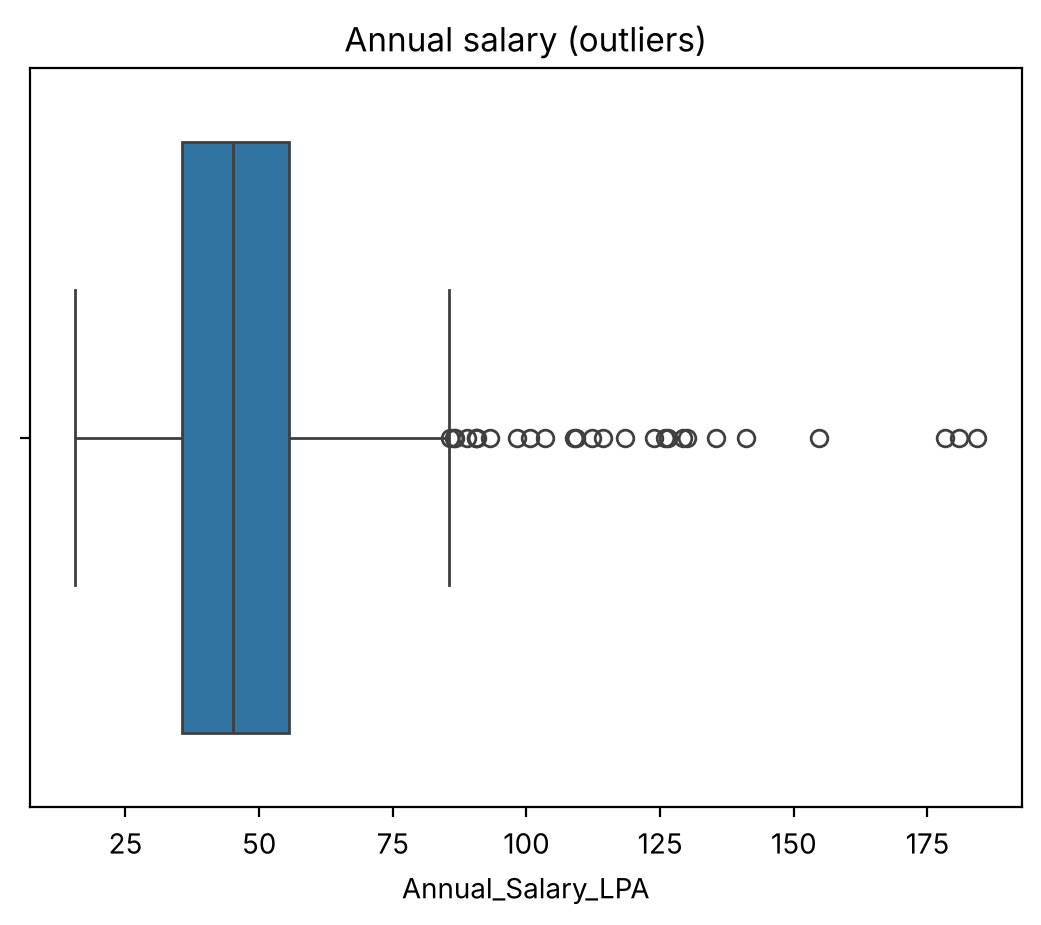

[184.19, 180.81, 178.33, 154.77, 140.99, 135.52, 129.94, 129.2, 126.56, 126.0, 123.76, 118.49, 114.25, 112.21, 109.21, 108.86, 103.42, 100.73, 98.32, 93.13]


In [11]:
sns.boxplot(data['Annual_Salary_LPA'], orient='h')
plt.title('Annual salary (outliers)')
plt.savefig('charts/salary_box.png', dpi=150, bbox_inches='tight')
plt.show()
print(sorted(data['Annual_Salary_LPA'], reverse=True)[:20])

In [12]:
# Remove extreme salaries (above 100 LPA)
out = data['Annual_Salary_LPA'] > 100
stats['salary_outliers'] = int(out.sum())
data = data[~out]
stats['rows_clean'] = len(data)
data.shape

(4963, 15)

## 3. Exploratory analysis

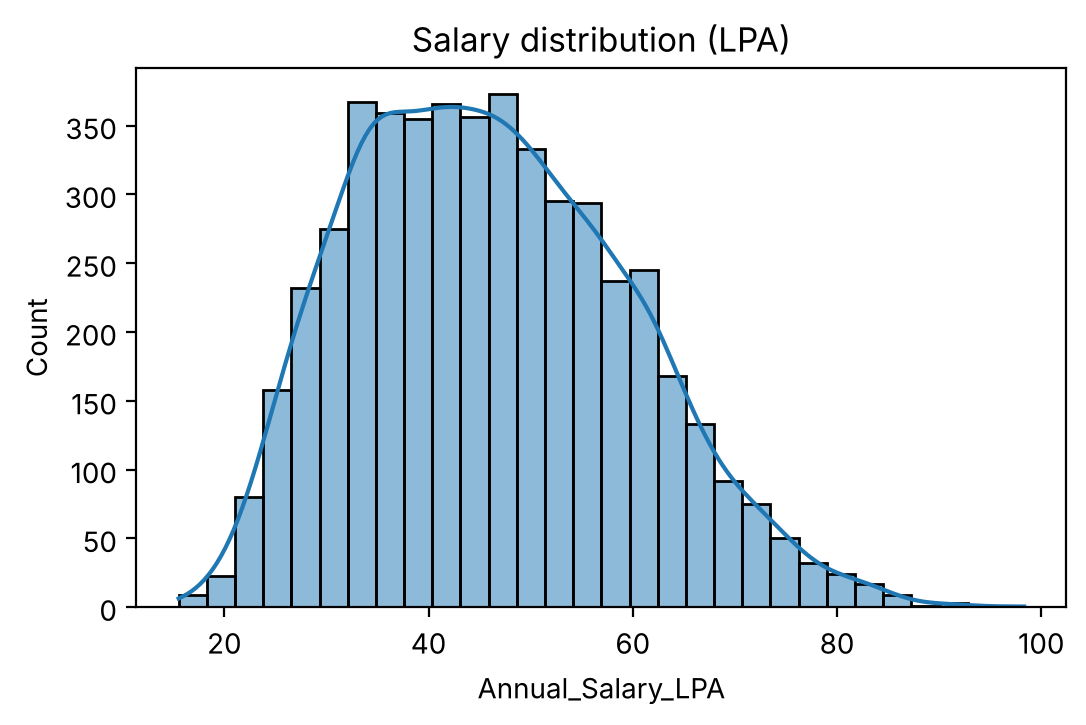

In [13]:
plt.figure(figsize=(6,3.5))
sns.histplot(data['Annual_Salary_LPA'], bins=30, kde=True)
plt.title('Salary distribution (LPA)')
plt.savefig('charts/salary_dist.png', dpi=150, bbox_inches='tight')
plt.show()

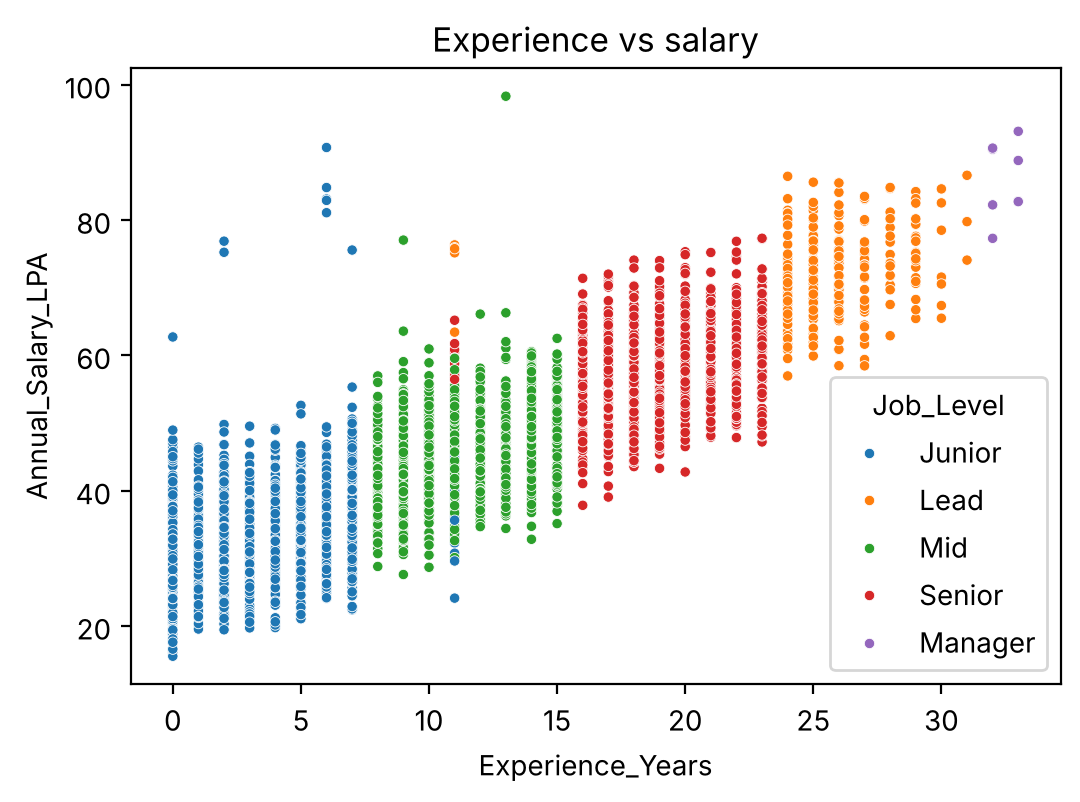

In [14]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Experience_Years', y='Annual_Salary_LPA', hue='Job_Level', data=data, s=14)
plt.title('Experience vs salary')
plt.savefig('charts/exp_salary.png', dpi=150, bbox_inches='tight')
plt.show()

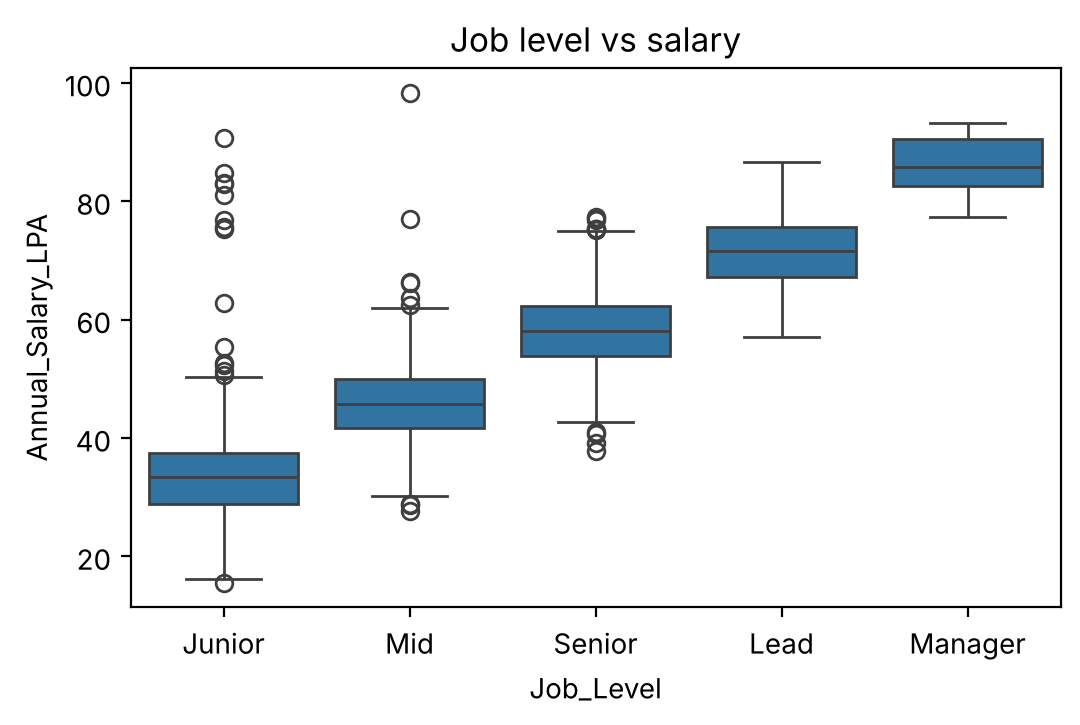

In [15]:
plt.figure(figsize=(6,3.5))
sns.boxplot(x='Job_Level', y='Annual_Salary_LPA', data=data, order=['Junior','Mid','Senior','Lead','Manager'])
plt.title('Job level vs salary')
plt.savefig('charts/level_salary.png', dpi=150, bbox_inches='tight')
plt.show()

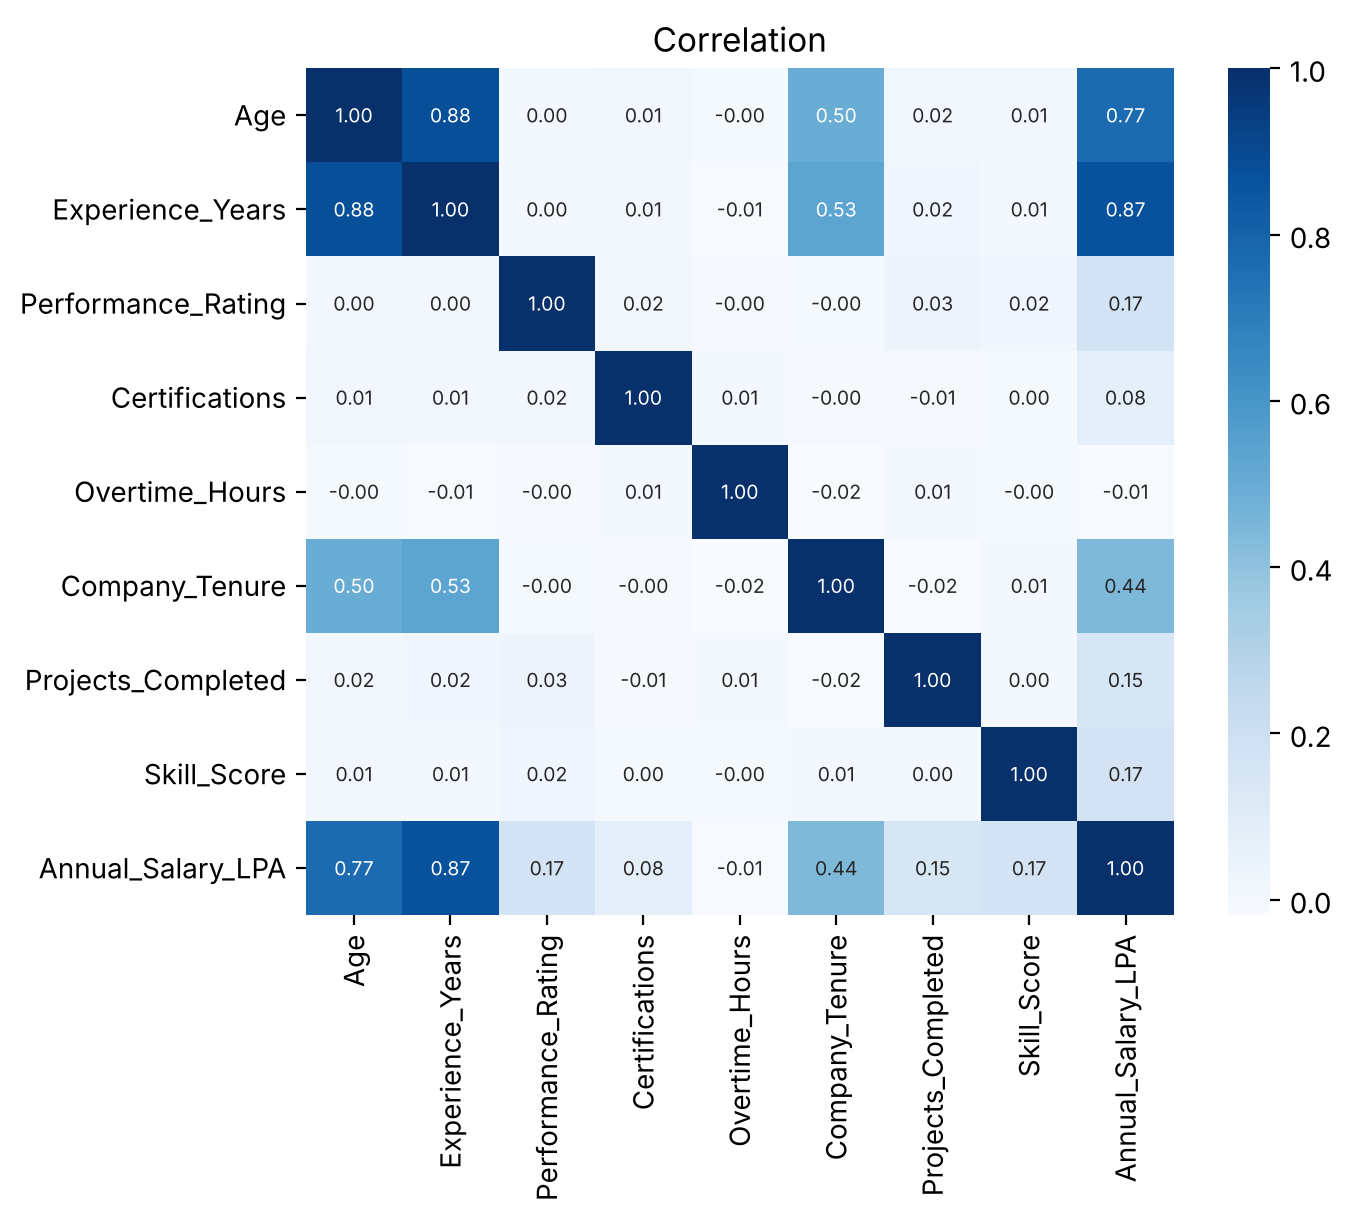

In [16]:
plt.figure(figsize=(7,5.5))
sns.heatmap(data.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='Blues', annot_kws={'size':7})
plt.title('Correlation')
plt.savefig('charts/corr.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Encoding
Text columns are converted to numbers (education and job level are ordered).

In [17]:
data['Gender'] = data['Gender'].map({'Female':0,'Male':1})
data['Education'] = data['Education'].map({'Diploma':0,'Bachelor':1,'Master':2,'PhD':3})
data['Department'] = data['Department'].map({'HR':0,'IT':1,'Marketing':2,'Operations':3,'Sales':4})
data['Job_Level'] = data['Job_Level'].map({'Junior':0,'Mid':1,'Senior':2,'Lead':3,'Manager':4})
data['Remote_Work'] = data['Remote_Work'].map({'No':0,'Yes':1})
data['City'] = data['City'].map({'Chennai':0,'Delhi':1,'Hyderabad':2,'Mumbai':3})
data.isnull().sum().sum()

np.int64(0)

In [18]:
x = data.drop('Annual_Salary_LPA', axis=1)
y = data['Annual_Salary_LPA']
x.head()

,Age,Gender,Education,Experience_Years,Department,Job_Level,Performance_Rating,Certifications,Overtime_Hours,Remote_Work,City,Company_Tenure,Projects_Completed,Skill_Score
0,28.0,1,2,6.0,3,0,1,4,15,1,0,6,5,97.0
1,26.0,0,1,5.0,3,0,2,3,32,0,1,0,18,62.0
2,31.0,0,1,5.0,2,0,4,5,17,1,2,4,7,98.0
3,59.0,0,1,29.0,4,3,3,0,46,0,3,14,18,57.0
4,23.0,0,1,0.0,4,0,2,4,5,1,2,0,28,56.0


## 5. Train / test split

In [19]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)
x_train.shape, x_test.shape

((3970, 14), (993, 14))

## 6. Train and compare models

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn import metrics

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(x_train, y_train)
    p = m.predict(x_test)
    rows.append([name, metrics.r2_score(y_test, p), metrics.mean_absolute_error(y_test, p), np.sqrt(metrics.mean_squared_error(y_test, p))])
results = pd.DataFrame(rows, columns=['Model', 'R2_Score', 'MAE', 'RMSE'])
results.to_csv('charts/results.csv', index=False)
results

,Model,R2_Score,MAE,RMSE
0,Linear Regression,0.869377,3.186369,4.902690
1,Random Forest,0.864944,3.296406,4.985186
2,Gradient Boosting,0.885103,2.923671,4.598101
3,XGBoost,0.887796,2.856114,4.543914


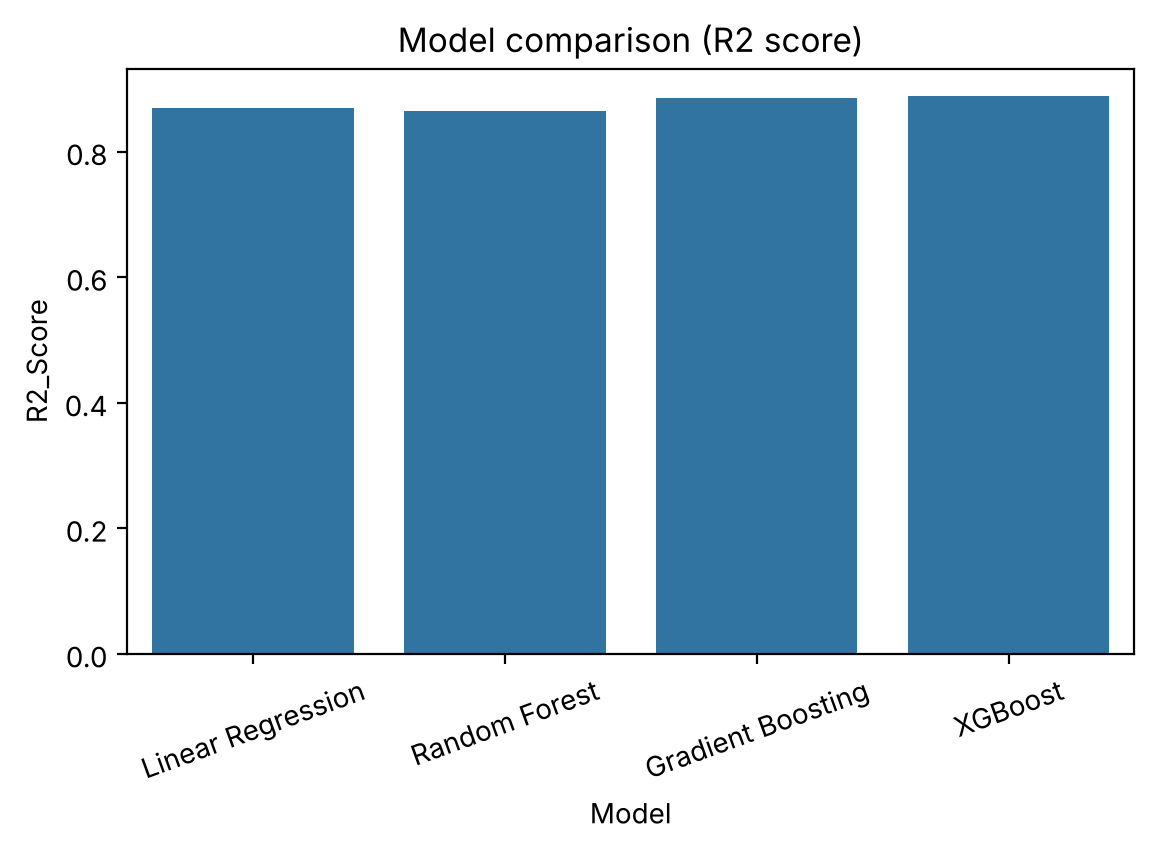

In [21]:
plt.figure(figsize=(6.5,3.8))
sns.barplot(x='Model', y='R2_Score', data=results)
plt.xticks(rotation=20)
plt.title('Model comparison (R2 score)')
plt.savefig('charts/model_compare.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Best model: actual vs predicted and feature importance

Best model: XGBoost


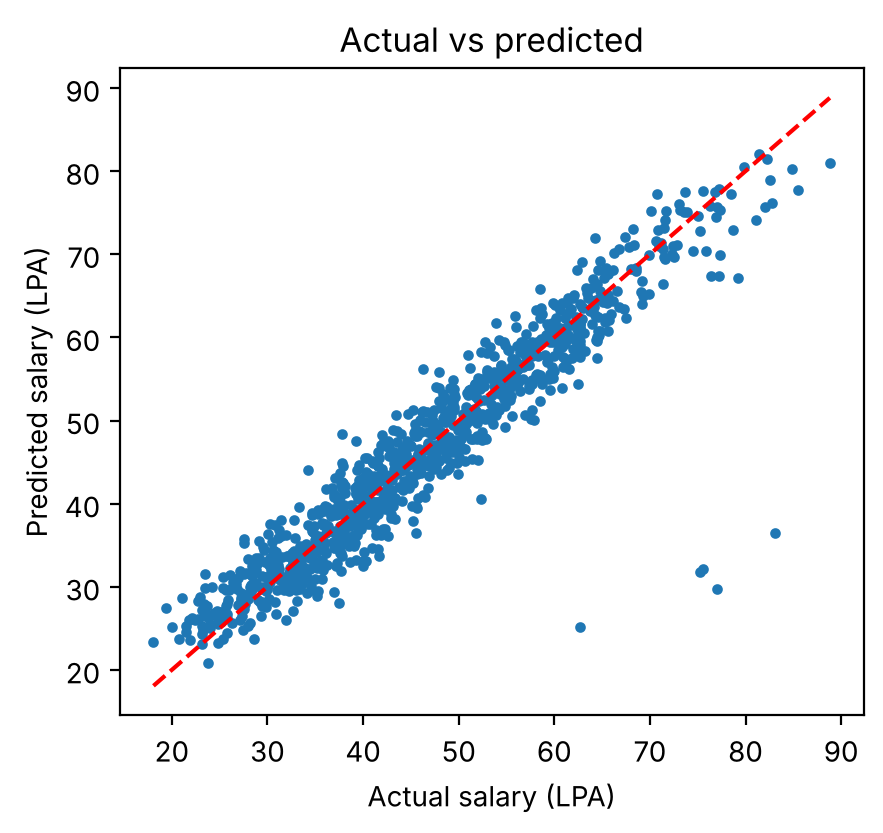

In [22]:
best = models[results.sort_values('R2_Score', ascending=False).iloc[0]['Model']]
print('Best model:', results.sort_values('R2_Score', ascending=False).iloc[0]['Model'])
pred = best.predict(x_test)
plt.figure(figsize=(4.8,4.2))
plt.scatter(y_test, pred, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual salary (LPA)'); plt.ylabel('Predicted salary (LPA)'); plt.title('Actual vs predicted')
plt.savefig('charts/actual_vs_pred.png', dpi=150, bbox_inches='tight')
plt.show()

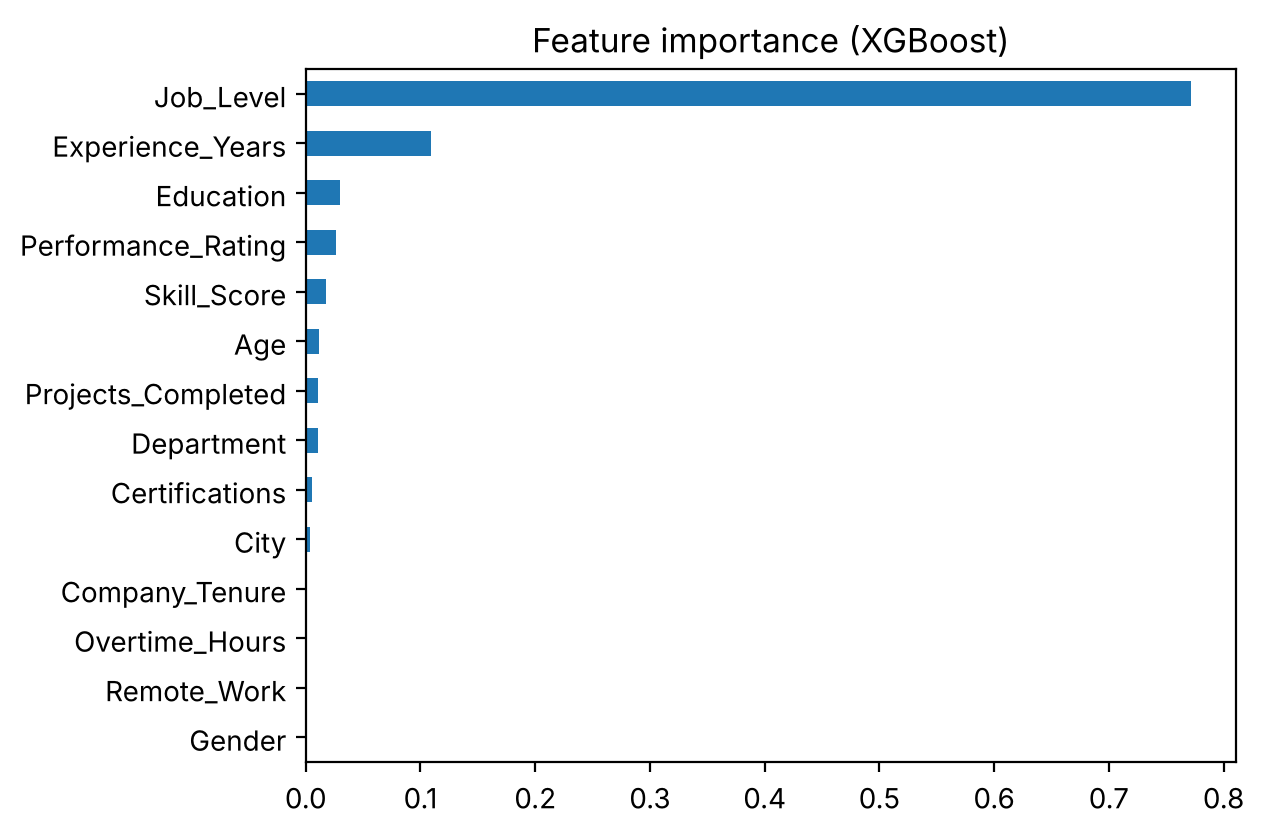

In [23]:
imp = pd.Series(models['XGBoost'].feature_importances_, index=x.columns).sort_values()
imp.plot(kind='barh', figsize=(6,4.5), title='Feature importance (XGBoost)')
plt.savefig('charts/importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Save the final model
The best model is retrained on the full data and saved as `.pkl` (joblib) and `.json`.

In [24]:
final_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
final_model.fit(x, y)
joblib.dump(final_model, 'salary_model.pkl')
final_model.save_model('salary_model.json')
json.dump(stats, open('charts/stats.json', 'w'))
print('saved')

saved


## 9. Test the saved model

In [25]:
model = joblib.load('salary_model.pkl')
sample = pd.DataFrame({'Age':[28],'Gender':[1],'Education':[2],'Experience_Years':[6],'Department':[1],'Job_Level':[0],'Performance_Rating':[3],'Certifications':[4],'Overtime_Hours':[15],'Remote_Work':[1],'City':[0],'Company_Tenure':[6],'Projects_Completed':[5],'Skill_Score':[97]})[x.columns]
print('Predicted salary: {:.2f} LPA'.format(model.predict(sample)[0]))

Predicted salary: 40.52 LPA
